In [259]:
import pandas as pd
from storage import OfferStorage
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score, cross_validate, learning_curve
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import optuna

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [260]:
df = pd.read_csv("offers_dataset.csv")

train_set, test_set = train_test_split(df, test_size=0.2, random_state=42)
explore_df = train_set.copy()

In [261]:
df.describe()

,id,price_per_person,duration_days,hotel_stars,average_rating,review_count,has_sea_view,number_of_restaurants,number_of_bars,number_of_pools,is_wifi_free,is_sunbed_included,distance_to_beach_meters,distance_to_center_meters,is_direct_flight,is_transfer_included,is_public_transport_nearby
count,3823.000000,3823.000000,3823.000000,3610.000000,3071.000000,3496.000000,2549.000000,3129.000000,3152.000000,3339.000000,3635.000000,3403.000000,3686.000000,2823.000000,1871.000000,2782.00000,1511.000000
mean,1912.000000,3085.050092,6.635888,4.153601,5.906024,318.655892,0.167909,2.788111,3.102475,3.362384,0.937001,0.753747,266.272382,9087.672689,0.943346,0.81560,0.931833
std,1103.749368,1990.893271,1.901496,0.743975,1.757523,569.908006,0.373859,2.035060,1.974279,4.592486,0.242994,0.430891,684.430815,13416.894192,0.231242,0.38788,0.252115
min,1.000000,269.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
25%,956.500000,1904.000000,5.000000,4.000000,4.500000,38.000000,0.000000,1.000000,2.000000,2.000000,1.000000,1.000000,0.000000,1000.000000,1.000000,1.00000,1.000000
50%,1912.000000,2550.000000,8.000000,4.000000,5.300000,139.000000,0.000000,2.000000,3.000000,2.000000,1.000000,1.000000,50.000000,3000.000000,1.000000,1.00000,1.000000
75%,2867.500000,3603.500000,8.000000,5.000000,7.700000,357.000000,0.000000,4.000000,4.000000,3.000000,1.000000,1.000000,300.000000,13000.000000,1.000000,1.00000,1.000000
max,3823.000000,24374.000000,15.000000,5.500000,10.000000,11554.000000,1.000000,18.000000,23.000000,36.000000,1.000000,1.000000,13000.000000,130000.000000,1.000000,1.00000,1.000000


In [262]:
attributes_info = pd.DataFrame({
    'Type of data': explore_df.dtypes,
    'Missing values (%)': (explore_df.isna().sum() / len(explore_df) * 100).round(2),
    'Unique values': explore_df.nunique()
})

attributes_info = attributes_info.sort_values(by='Missing values (%)', ascending=False)
attributes_info

,Type of data,Missing values (%),Unique values
flight_return_time,str,83.39,131
flight_departure_time,str,72.76,171
is_public_transport_nearby,float64,60.14,2
is_direct_flight,float64,50.65,2
has_sea_view,float64,33.03,2
is_transfer_included,float64,26.78,2
distance_to_center_meters,float64,26.75,86
average_rating,float64,19.95,73
number_of_restaurants,float64,18.44,12
number_of_bars,float64,17.79,18


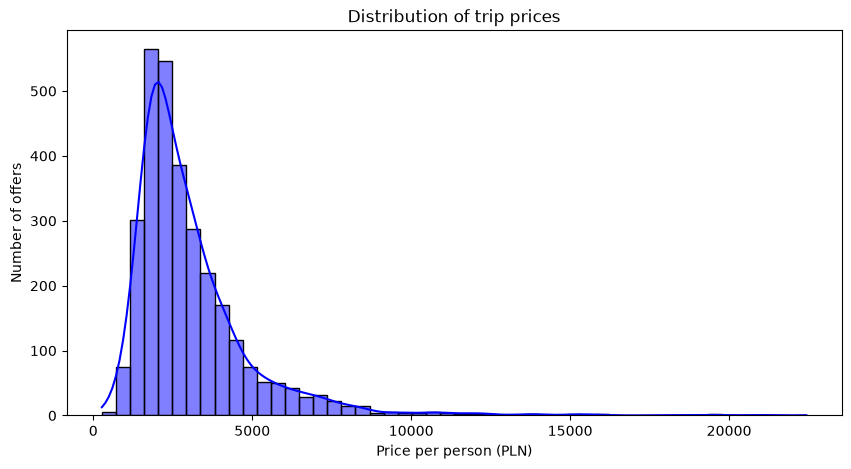

Correlations with price_per_person:
duration_days                 0.54
is_transfer_included          0.27
hotel_stars                   0.25
average_rating                0.17
is_wifi_free                  0.16
has_sea_view                  0.14
id                            0.13
is_sunbed_included            0.07
number_of_bars                0.07
number_of_restaurants         0.06
distance_to_beach_meters      0.02
distance_to_center_meters    -0.05
number_of_pools              -0.08
review_count                 -0.14
is_public_transport_nearby   -0.16
is_direct_flight             -0.55
Name: price_per_person, dtype: float64


In [263]:
plt.figure(figsize=(10, 5))
sns.histplot(explore_df['price_per_person'], bins=50, kde=True, color='blue')
plt.title('Distribution of trip prices')
plt.xlabel('Price per person (PLN)')
plt.ylabel('Number of offers')
plt.show()

print("Correlations with price_per_person:")
numeric_cols = explore_df.select_dtypes(include=[np.number])
correlations = numeric_cols.corr()['price_per_person'].sort_values(ascending=False).drop('price_per_person')
print(correlations.round(2))

In [264]:
explore_df['is_direct_flight'].value_counts(dropna=False)

is_direct_flight
NaN    1549
1.0    1426
0.0      83
Name: count, dtype: int64

In [265]:
przesiadki_df = explore_df[explore_df['is_direct_flight'] == 0.0]

print("Średnia cena:")
print("- Lot z przesiadką (0.0):", przesiadki_df['price_per_person'].mean().round(2), "PLN")
print("- Lot bezpośredni (1.0):", explore_df[explore_df['is_direct_flight'] == 1.0]['price_per_person'].mean().round(2), "PLN")
print("- Brak samolotu / dojazd własny (NaN):", explore_df[explore_df['is_direct_flight'].isna()]['price_per_person'].mean().round(2), "PLN")
print("-" * 30)

kolumny_do_podgladu = ['price_per_person', 'country', 'hotel_stars', 'duration_days', 'is_transfer_included'] 

przesiadki_df[kolumny_do_podgladu].sort_values(by='price_per_person', ascending=False).head(10)

Średnia cena:
- Lot z przesiadką (0.0): 9035.05 PLN
- Lot bezpośredni (1.0): 3262.04 PLN
- Brak samolotu / dojazd własny (NaN): 2601.29 PLN
------------------------------


,price_per_person,country,hotel_stars,duration_days,is_transfer_included
2979,22432.0,Brazil,NaN,11,1.0
1443,21145.0,Mauritius,5.0,10,1.0
1645,20644.0,Mauritius,5.0,10,1.0
1855,19624.0,Mauritius,5.0,10,1.0
3202,19405.0,Mauritius,5.0,10,1.0
1851,18524.0,Mauritius,5.0,10,1.0
1477,16117.0,Indonesia,5.0,12,1.0
1937,15806.0,Indonesia,5.0,13,1.0
3198,15455.0,Mauritius,5.0,10,1.0
3199,15295.0,Mauritius,5.0,10,1.0


Warto podzielić zmienne na trzy grupy. Skoro celujemy w model XGBoost, to podejście do danych wygląda tak:

1. Najwazniejsze cechy:
 - duration_days i hotel_stars: Im dłuzszy wyjazd i wiecej gwiazdek, tym drozej, zgadza się
 - is_direct_flight: ujemna korelacja (-0,53), loty z przesiadkami znacznie drozsze, lecz duzo braków. Aczkolwiek moglibyśmy tez załozyć, ze w ofertach, w których nie została odnaleziona informacja o locie, oznacza, ze dojazd jest na własną rękę, co za tym idzie, cena wycieczki maleje, pomoze nam wykryc te dalsze kierunki
 - is_transfer_included: wysoka korelacja z atrybutem wyjsciowym. Transfery z lotniska bywają drogie, co za tym idzie, jego obecność podnosi cenę

 2. Braki w danych
 - Atrybuty numeryczne, np. 'average_rating', 'distance_to_center_meters', itp. mają tez calkiem sporo brakow, ale mniej niz 50%. Skoro chcemy uzywac drzew decyzyjnych, to zostawiamy te kolumny. Drzewa radzą sobie z wartościami NaN i potrafią same wyciągnąć wnioski
 - Zmienne binarne (np. 'has_sea_view', 'is_wifi_free): Brak informacji o tych kolumnach, raczej stanowi dla modelu informację, ze tych udogodnien nie ma. Zazwyczaj w swoich ofertach, jezeli np wifi jest darmowe, to się tym chwalą w opisie oferty.

 3. Do wyrzucenia
 - ID, URL, scraped_at: metadane ze scrapowania, do przewidywania ceny nie wnosza zadnych informacji
 - hotel_name: za duzo unikalnych nazw, łatwy overfitting
 - flight_return_time, flight_departure_time: Zbyt duzo wartosci NaN w danych, zeby dalo sie wyciagnac jakikolwiek sensowny wzorzec

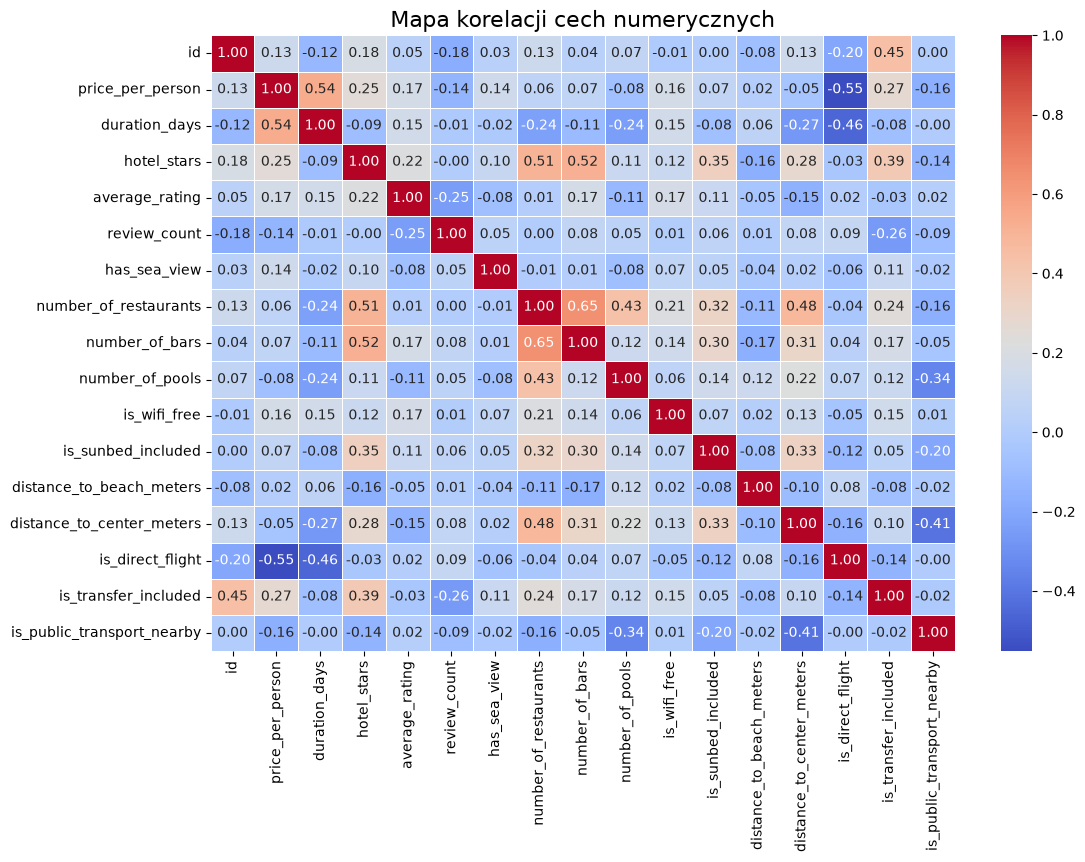

In [266]:
corr_matrix = explore_df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Mapa korelacji cech numerycznych', fontsize=16)
plt.show()

Najkrótszy wyjazd (dni): 3
Najdłuższy wyjazd (dni): 15

Top 5 najczęstszych długości pobytu:
duration_days
8    1396
4     617
5     497
7     284
9     102
Name: count, dtype: int64


/var/folders/sw/_qfdhp6j407_9npq2dbz7t0w0000gp/T/ipykernel_35008/4016047169.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=explore_df, x='duration_days', y='price_per_person', palette='viridis')


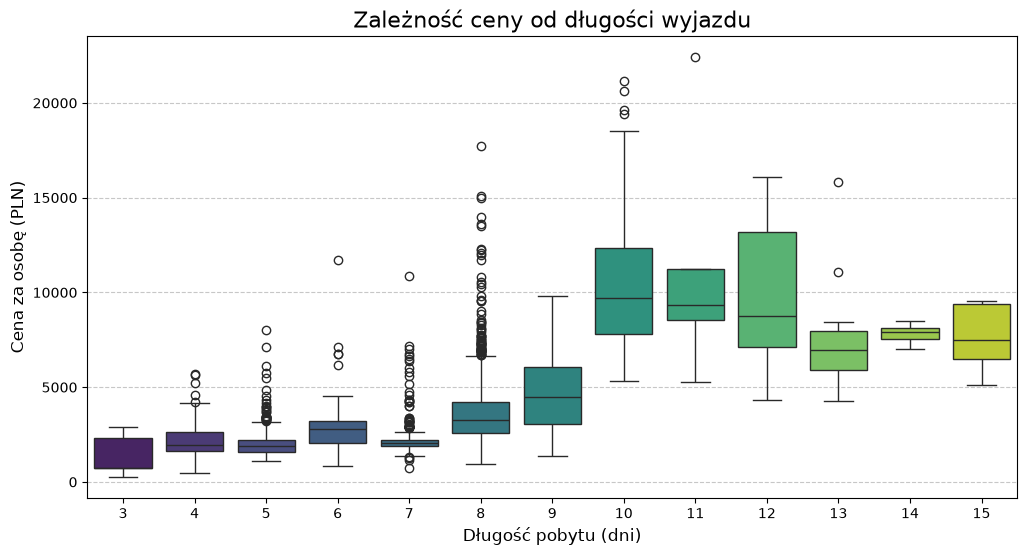

In [267]:
print("Najkrótszy wyjazd (dni):", explore_df['duration_days'].min())
print("Najdłuższy wyjazd (dni):", explore_df['duration_days'].max())
print("\nTop 5 najczęstszych długości pobytu:")
print(explore_df['duration_days'].value_counts().head())

plt.figure(figsize=(12, 6))
sns.boxplot(data=explore_df, x='duration_days', y='price_per_person', palette='viridis')
plt.title('Zależność ceny od długości wyjazdu', fontsize=16)
plt.xlabel('Długość pobytu (dni)', fontsize=12)
plt.ylabel('Cena za osobę (PLN)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

/var/folders/sw/_qfdhp6j407_9npq2dbz7t0w0000gp/T/ipykernel_35008/3936484310.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_duration, x='duration_days', y='country', palette='magma')


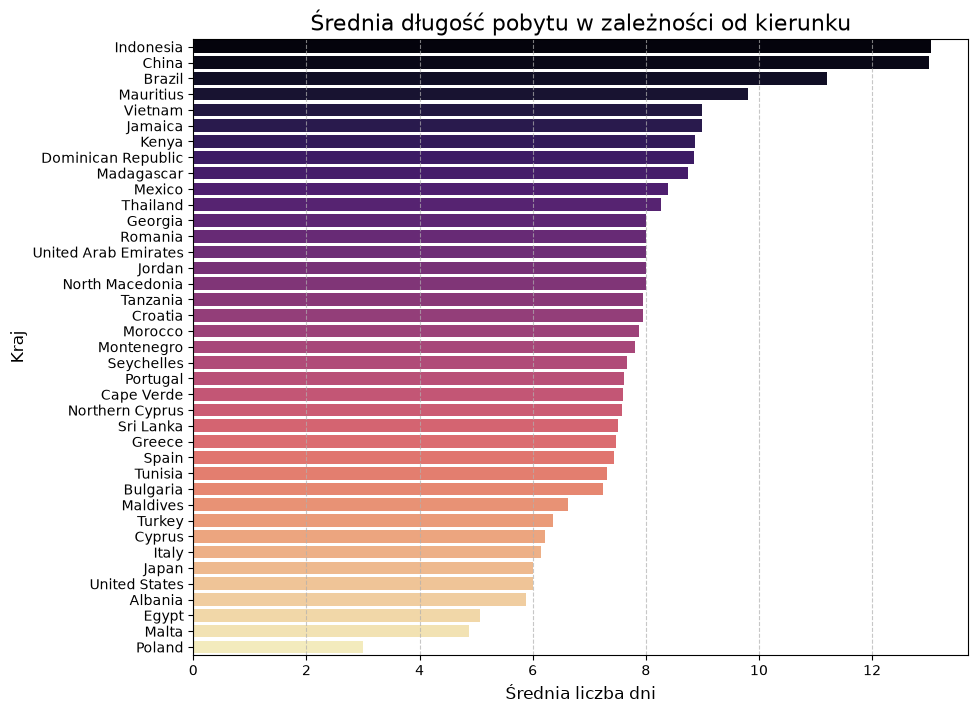

In [268]:
avg_duration = explore_df.groupby('country')['duration_days'].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10, 8)) 
sns.barplot(data=avg_duration, x='duration_days', y='country', palette='magma')
plt.title('Średnia długość pobytu w zależności od kierunku', fontsize=16)
plt.xlabel('Średnia liczba dni', fontsize=12)
plt.ylabel('Kraj', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

DURATION_DAYS: czemu 10 dni drozsze niz 13+?

Z naszej heatmapy wiemy, ze korelacja dlugosci pobytu z ceną jest bardzo wysoka, czyli im dluzsze wakacje, tym wyzsza cena. Jednak po rozbiciu tych danych, wychodzą inne ciekawe informacje

 - Anomalia przy 10 dniach: Z boxplota wyszedł trend rosnący, ale przy wyjazdach 10-dniowych mamy duzy przeskok: Mediana ceny przebija 10000PLN. A jeszcze dłuzsze pobyty okazuja sie statystycznie tansze

 Z ostatniego wykresu widzimy, ze najdluzsze pobyty zazwyczaj odbywają się w krajach egzotycznych, które faktycznie są drozsze

WNIOSEK: Bardzo wazna cecha, przy dalszym przygotowaniu danych i inzynierii cech bedziemy musieli wziac pod uwage tą zaleznosc miedzy liczba dni, a krajem wyjazdu

/var/folders/sw/_qfdhp6j407_9npq2dbz7t0w0000gp/T/ipykernel_35008/2582090966.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=country_stats, x='avg_price', y='country', palette='coolwarm')


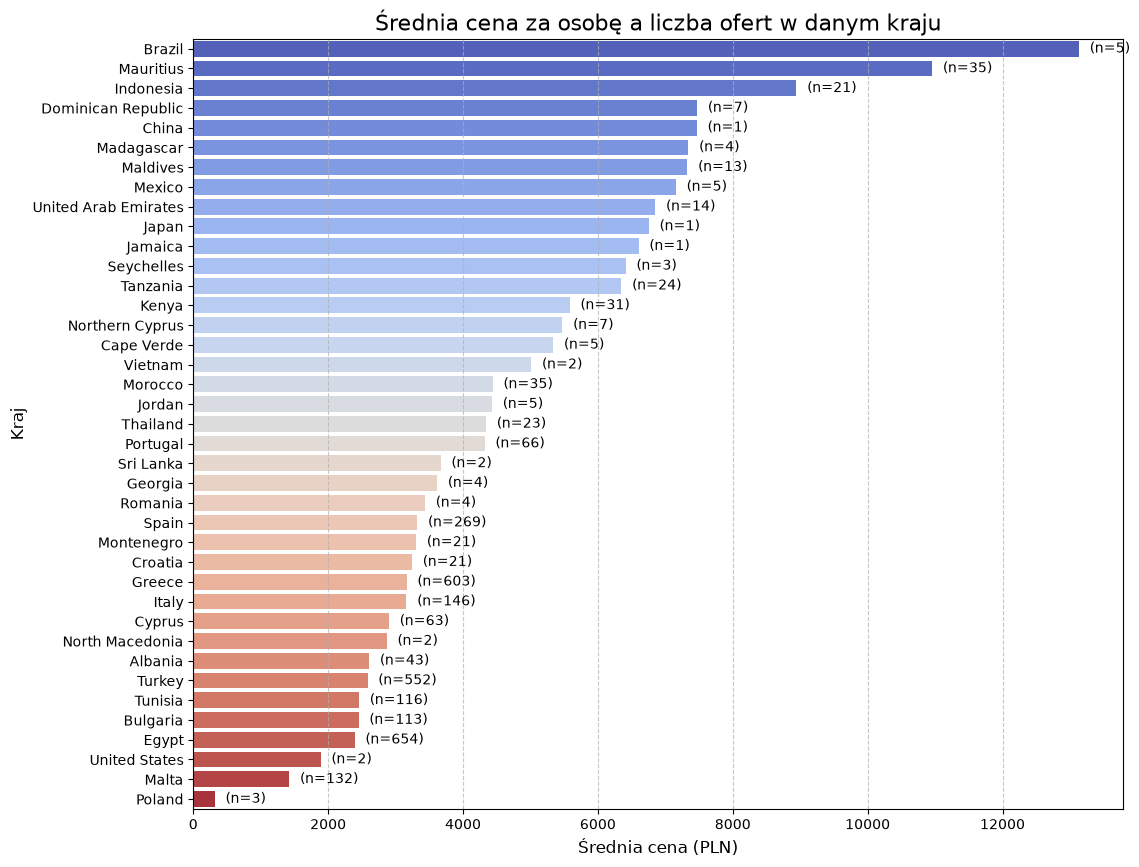

In [269]:
country_stats = explore_df.groupby('country').agg(
    avg_price=('price_per_person', 'mean'),
    count=('price_per_person', 'count')
).sort_values(by='avg_price', ascending=False).reset_index()

plt.figure(figsize=(12, 10))
sns.barplot(data=country_stats, x='avg_price', y='country', palette='coolwarm')

for index, row in country_stats.iterrows():
    plt.text(row['avg_price'] + 100, index, f" (n={int(row['count'])})", color='black', va='center', fontsize=10)

plt.title('Średnia cena za osobę a liczba ofert w danym kraju', fontsize=16)
plt.xlabel('Średnia cena (PLN)', fontsize=12)
plt.ylabel('Kraj', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

COUNTRY

Widzimy wyrazna roznice, miedzy tanimi, a drogimi kierunkami wycieczek.

WNIOSEK: z racji tego, ze uzywamy XGBoost, nie bedziemy psuc danych klasycznym One-Hot Encodingiem (bo stworzylby gigantyczna macierz i spowolnil drzewa). Nowe wersje XGBoosta wspieraja zmienne kategoryczne. Musimy jedynie zmienic typ tej kolumny w Pandas na category i wlaczymy flage enable_categorical=True w parametrach modelu.

In [270]:
liczba_regionow = explore_df['region'].nunique()
print(f"Liczba unikalnych regionów: {liczba_regionow}\n")

region_stats = explore_df.groupby('region').agg(
    liczba_ofert=('price_per_person', 'count'),
    srednia_cena=('price_per_person', 'mean')
).sort_values(by='liczba_ofert', ascending=False).head(15)

print("Top 15 najpopularniejszych regionów:")
print(region_stats.round(2))

Liczba unikalnych regionów: 452

Top 15 najpopularniejszych regionów:
                 liczba_ofert  srednia_cena
region                                     
Hurghada                  355       2301.95
Marsa Alam                221       2326.57
Alanya                    192       1832.69
Kreta                     134       2542.53
Zakynthos                  97       2848.18
Side                       83       2576.73
Riwiera Turecka            74       2434.78
Rodos                      68       2662.46
Mellieha                   54       1508.15
Bugibba i Qawra            52        934.75
Kos                        50       2627.06
Majorka                    49       3384.47
Kalabria                   49       2201.82
Korfu                      47       3423.34
Słoneczny Brzeg            41       2447.95


REGION

Mamy ponad 390 unikalnych regionów (wysoka kardynalnosc i dlugi ogon). Ale za to top 15 pokazuje, ze ta cecha jest wazna, poniewaz widac, ze region faktycznie ma znaczenie dla niektorych kierunkow

WNIOSEK: Podobnie jak przy krajach, zostawiamy tę kolumnę i przypisujemy do niej etykietę category. Jednak mając tak duzo regionow, gdzie wiekszosc pewnie wystepuje po 1-2 razy, musimy uwazac na overfitting. Wobec tego, wszystkie regiony ktore wystepuja w zbiorze np. mniej niz 5-10 razy, wrzucimy do jednej kategorii "Inne". Dzięki temu zachowamy najwazniejsze informacje i pozbedziemy sie szumu.



/var/folders/sw/_qfdhp6j407_9npq2dbz7t0w0000gp/T/ipykernel_35008/572443197.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=explore_df, x='departure_month', palette='viridis', ax=axes[0])


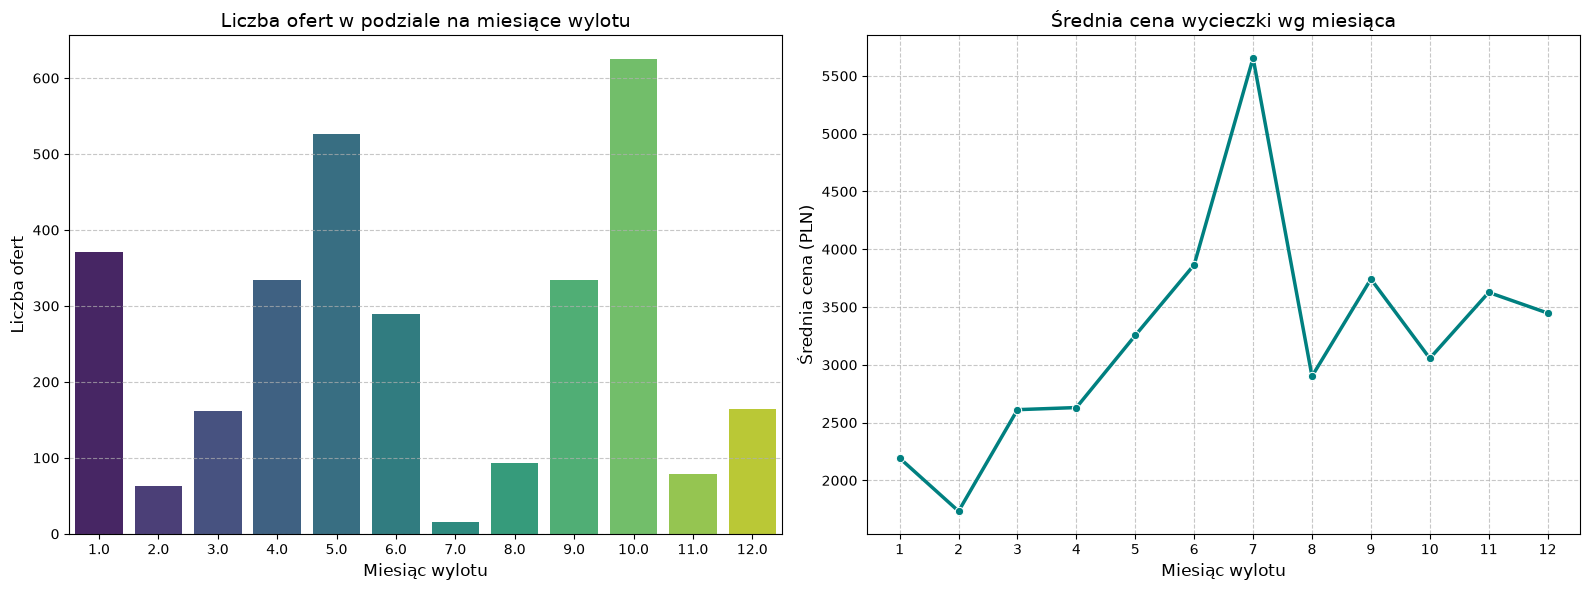

In [271]:
explore_df['departure_date'] = pd.to_datetime(explore_df['departure_date'])

explore_df['departure_month'] = explore_df['departure_date'].dt.month

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.countplot(data=explore_df, x='departure_month', palette='viridis', ax=axes[0])
axes[0].set_title('Liczba ofert w podziale na miesiące wylotu', fontsize=14)
axes[0].set_xlabel('Miesiąc wylotu', fontsize=12)
axes[0].set_ylabel('Liczba ofert', fontsize=12)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

monthly_price = explore_df.groupby('departure_month')['price_per_person'].mean().reset_index()
sns.lineplot(data=monthly_price, x='departure_month', y='price_per_person', 
             marker='o', color='teal', linewidth=2.5, ax=axes[1])
axes[1].set_title('Średnia cena wycieczki wg miesiąca', fontsize=14)
axes[1].set_xlabel('Miesiąc wylotu', fontsize=12)
axes[1].set_ylabel('Średnia cena (PLN)', fontsize=12)
axes[1].set_xticks(range(1, 13)) 
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

DEPARTURE_DATE

data wylotu, to jeden z wazniejszych czynnikow, ktory wplywa na cene wycieczki. Aczkolwiek data wylotu w formacie YYYY-MM-DD jest nieczytelna dla modeli matematycznych, dlatego na etapie inzynierii cech wyciagniemy z niej sam miesiac. 

WNIOSKI: Tworzymy kolumne departure_month, a departure_date usuwamy

/var/folders/sw/_qfdhp6j407_9npq2dbz7t0w0000gp/T/ipykernel_35008/941880801.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(data=stars_stats, x='hotel_stars', y='avg_price', palette='viridis')


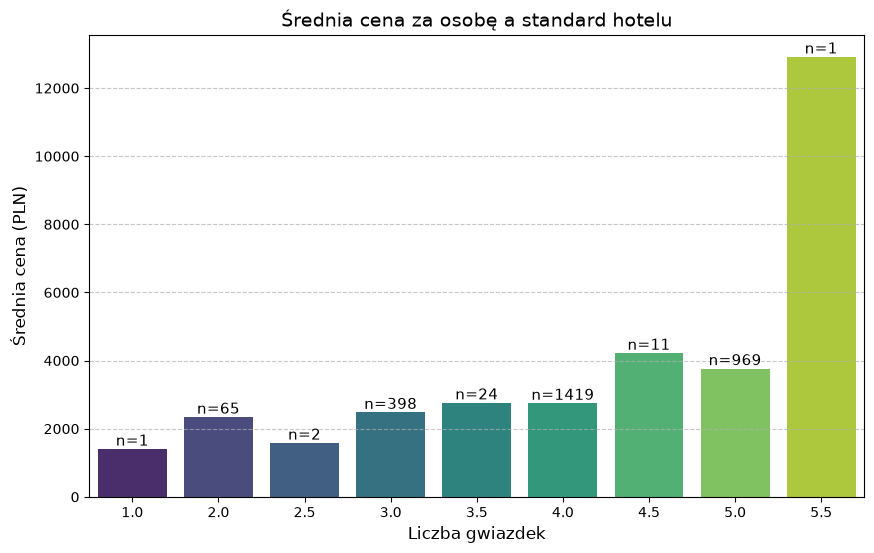

In [272]:
stars_stats = explore_df.groupby('hotel_stars').agg(
    avg_price=('price_per_person', 'mean'),
    count=('price_per_person', 'count')
).reset_index()

plt.figure(figsize=(10, 6))
bars = sns.barplot(data=stars_stats, x='hotel_stars', y='avg_price', palette='viridis')

for index, row in stars_stats.iterrows():
    plt.text(index, row['avg_price'] + 100, f"n={int(row['count'])}", color='black', ha='center', fontsize=11)

plt.title('Średnia cena za osobę a standard hotelu', fontsize=14)
plt.xlabel('Liczba gwiazdek', fontsize=12)
plt.ylabel('Średnia cena (PLN)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

HOTEL_STARS

od razu widzimy, ze polowkowych kategorii (2.5, 3.5, 4.5, 5.5) jest bardzo mało i zniekształcają nam statystyki

WNIOSEK: Liczba gwiazdek, to mocna cecha, bo widać, ze cena rosnie wraz ze standardem, lecz musimy z pewnoscia zaokraglic wszystkie ceny do pelnych gwiazdek. Pozbedziemy sie w ten sposob szumu

Liczba braków w ocenach (NaN): 610


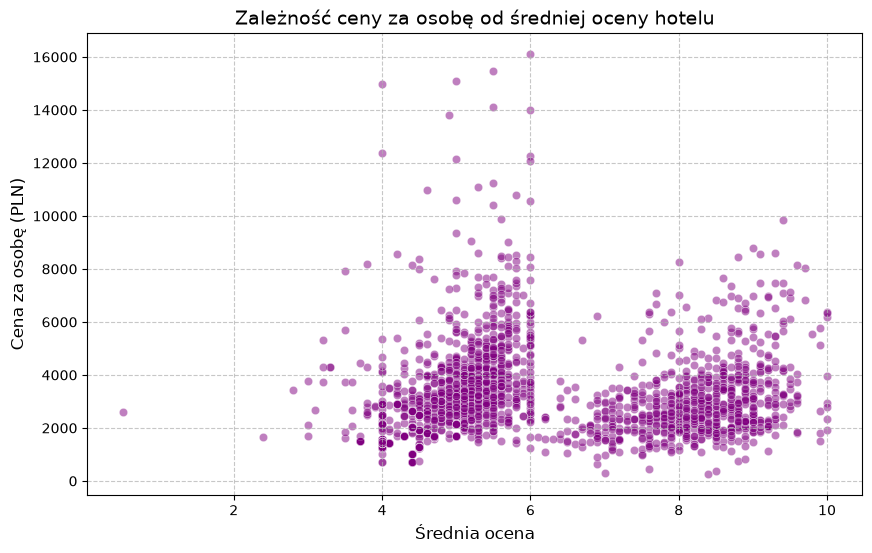

In [273]:
missing_ratings = explore_df['average_rating'].isna().sum()
print(f"Liczba braków w ocenach (NaN): {missing_ratings}")

plt.figure(figsize=(10, 6))
sns.scatterplot(data=explore_df, x='average_rating', y='price_per_person', alpha=0.5, color='purple')

plt.title('Zależność ceny za osobę od średniej oceny hotelu', fontsize=14)
plt.xlabel('Średnia ocena', fontsize=12)
plt.ylabel('Cena za osobę (PLN)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

AVERAGE_RATING

Mozemy zauwazyc pewien problem z danymi: punkty na osi X rozbily sie na dwie czesci: czesc konczy sie w okolicach oceny 5-6, a reszta dopiero w przedziale 8-10

Jest to wina roznych ocen na roznych portalach turystycznych
Lecz pomimo niespojnosci skali, zauwazalna jest korelacja z ceną

WNIOSEK: Przed przekazaniem danych do modelu, bedziemy musieli znormalizowac te oceny (np. przeliczyc wszystko do wspolnej skali 0-10)


REVIEW_COUNT:

sama liczba opinii nie wnosi nic do ceny wycieczki, ale za to wiemy, ze oferta z 8.9/10 i tysiącem opinii będzie miała większe znaczenie, niz oferta z 10/10 i jedną opinią

WNIOSEK: Połączymy average_rating i review_count, zeby utworzyc sensowna i cos wnoszaca ceche dla modelu

Liczba ofert dla poszczególnych typów pokoi:
room_type
Standard      2556
Economy        139
Studio          98
Apartment       73
Suite           49
Family          36
Apartament      28
Name: count, dtype: int64


/var/folders/sw/_qfdhp6j407_9npq2dbz7t0w0000gp/T/ipykernel_35008/1218517384.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=explore_df, x='room_type', y='price_per_person', palette='Set2')


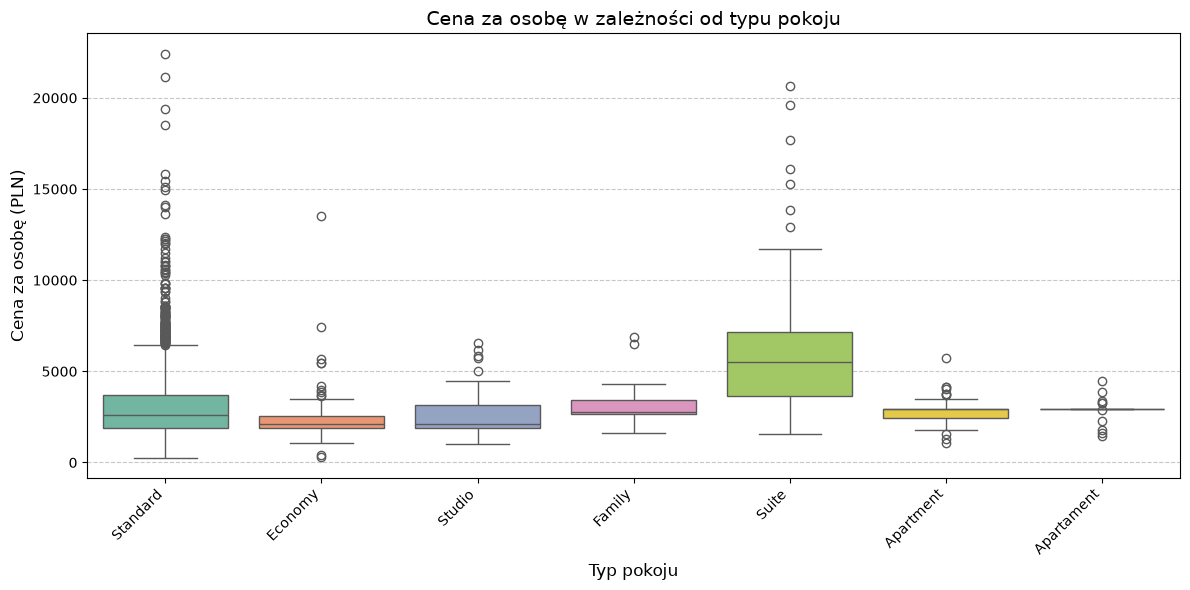

In [274]:
print("Liczba ofert dla poszczególnych typów pokoi:")
print(explore_df['room_type'].value_counts())

plt.figure(figsize=(12, 6))
sns.boxplot(data=explore_df, x='room_type', y='price_per_person', palette='Set2')

plt.title('Cena za osobę w zależności od typu pokoju', fontsize=14)
plt.xlabel('Typ pokoju', fontsize=12)
plt.ylabel('Cena za osobę (PLN)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

ROOM_TYPE

Większość typów trzyma sie blisko dosc niskiej mediany, za to przy Suite ceny ida mocno w gore

mamy tez duzo outlierow

Widac problem nazewnictwa (Apartment/Apartament)

Wniosek: Zanim kolumna trafi do modelu, musimy znormalizowac nazewnictwo (laczac apartamenty w jedna wspolna kategorie za pomoca slownika Pandas)

Proporcje cechy has_sea_view (%):
has_sea_view
0.0    83.06
1.0    16.94
Name: proportion, dtype: float64


/var/folders/sw/_qfdhp6j407_9npq2dbz7t0w0000gp/T/ipykernel_35008/2619341706.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=explore_df, x='has_sea_view', y='price_per_person', palette='Set2')


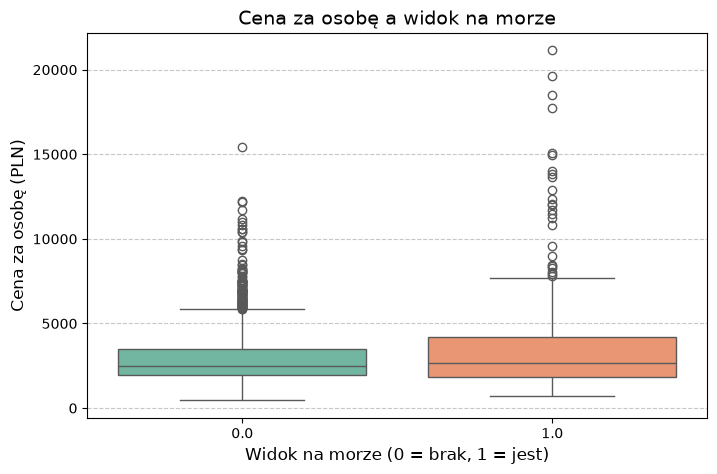

In [275]:
print("Proporcje cechy has_sea_view (%):")
print((explore_df['has_sea_view'].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(8, 5))
sns.boxplot(data=explore_df, x='has_sea_view', y='price_per_person', palette='Set2')
plt.title('Cena za osobę a widok na morze', fontsize=14)
plt.xlabel('Widok na morze (0 = brak, 1 = jest)', fontsize=12)
plt.ylabel('Cena za osobę (PLN)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

HAS_SEA_VIEW

dosyc niska korelacja z cena, ale sama zaleznosc jest jasna: za widok z morzem trzeba doplacic

WNIOSEK: baza jest calkiem zroznicowana, zostawiamy ceche i nic z nia nie robimy

/var/folders/sw/_qfdhp6j407_9npq2dbz7t0w0000gp/T/ipykernel_35008/2306714515.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(data=meal_stats, x='meal_plan', y='avg_price', palette='magma')


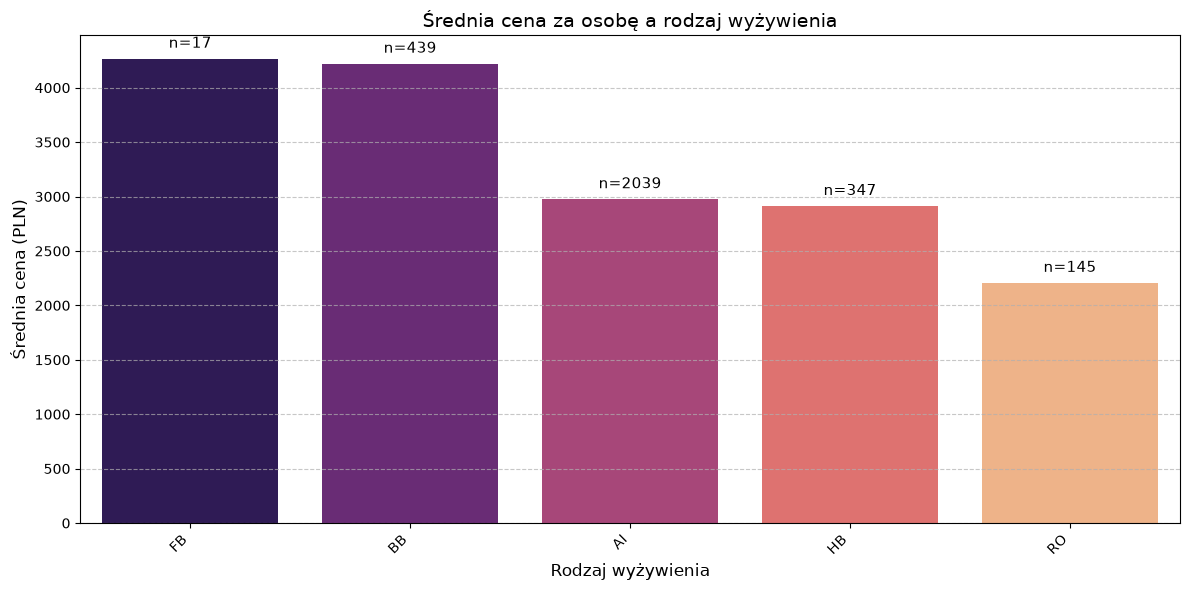

In [276]:
meal_stats = explore_df.groupby('meal_plan').agg(
    avg_price=('price_per_person', 'mean'),
    count=('price_per_person', 'count')
).reset_index().sort_values(by='avg_price', ascending=False)

plt.figure(figsize=(12, 6))
bars = sns.barplot(data=meal_stats, x='meal_plan', y='avg_price', palette='magma')

for index, row in meal_stats.reset_index().iterrows():
    plt.text(index, row['avg_price'] + 100, f"n={int(row['count'])}", color='black', ha='center', fontsize=11)

plt.title('Średnia cena za osobę a rodzaj wyżywienia', fontsize=14)
plt.xlabel('Rodzaj wyżywienia', fontsize=12)
plt.ylabel('Średnia cena (PLN)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

MEAL_PLAN

dosyc dziwna cecha, bo podejrzewalibysmy, ze All Inclusive bedzie najdrozszym wyborem. Okazuje sie jednak ze nie. Prawdopodobnie to dlatego, ze z opcją BB spotykamy sie raczej w drogich, luksusowych hotelach miejskich. Za to AI spotykane jest masowo w obleganych kierunkach typu egipt, bulgaria itp, gdzie nadrabiaja liczba turystow, co zbija ich ogolna srednia cenowa

opcja FB zaburza nam statystyki, bo mamy bardzo malo takich opcji w bazie, a sa bardzo wysoko cenowo

WNIOSEK: Wazny predyktor, zaledwie kilka unikalnych wartosci. Trzeba tylko zrobic enable_categorical=True. Warto tez przydzielic FB do HB, bo roznica miedzy nimi dla modelu nie bedzie duza, a pozbedziemy sie szumu i overfittingu

FLIGHT_DEPARTURE_TIME i FLIGHT_RETURN_TIME

za duzo brakow

WNIOSEK: usuwamy

NUMBER_OF_POOLS, NUMBER_OF_RESTAURANTS, NUMBER_OF_BARS

z heatmapy widzimy, ze korelacja z cena wcale nie jest satysfakcjonujaca. To pewnie dlatego, ze dla goscia nie liczy sie liczba, tylko fakt, czy w ogole takie rzeczy posiada

WNIOSEK: zamiast wrzucac do modelu liczby, ktore nic nie wniosa, przeksztalcimy kolumny w zmienne binarne (0/1). Sprawdzimy, czy fakt posiadania udogodnienia bedzie lepszym sygnalem

IS_WIFI_FREE

z heatmapy wynika, ze hotele z darmowym wifi mają wyzsza cene

WNIOSEK: zostawiamy kolumne bez zmian

IS_SUNBED_INCLUDED

mało braków, ale tez niska korelacja

WNIOSEK: szansa dla modelu na znalezienie dodatkowych regul, zostawiamy i nic z nia nie robimy


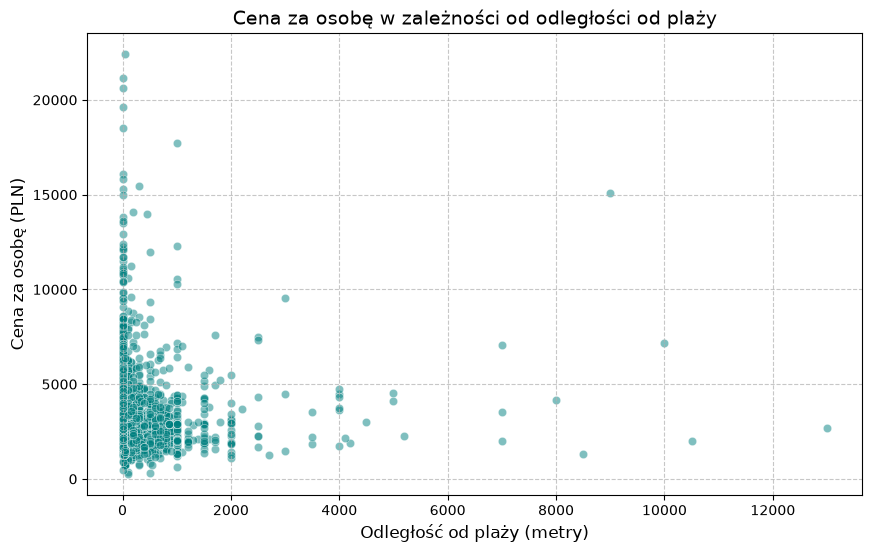

In [277]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=explore_df, x='distance_to_beach_meters', y='price_per_person', alpha=0.5, color='teal')

plt.title('Cena za osobę w zależności od odległości od plaży', fontsize=14)
plt.xlabel('Odległość od plaży (metry)', fontsize=12)
plt.ylabel('Cena za osobę (PLN)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

DISTANCE_TO_BEACH_METERS

nieliniowa zaleznosc, mala korelacja

WNIOSEK: zostawiamy, moze sie przyda

DISTANCE_TO_CENTER_METERS

Tutaj mamy delikatną, ujemną korelację (-0.06), co ma sporo sensu – im dalej od centrum, tym ceny lekko spadają. Sygnał nie jest super silny, bo w przypadku egzotycznych kurortów odległość od centrum lokalnej miejscowości rzadko kogo interesuje, za to w hotelach miejskich to absolutnie kluczowa sprawa.

WNIOSEK: zostawiamy

IS_DIRECT_FLIGHT

o tym juz wspominalam wczesniej, duzo brakow, ktore prawdopodobnie oznaczaja, ze po prostu transport nie jest w cenie wycieczki

WNIOSEK: Zostawiamy, ewentualnie mozemy zamienic NaN na nowa kategorie (np. -1) tworzac dla modelu 3 sygnaly: dojazd wlasny, lot bezposredni, lot z przesiadkami

Rozkład wartości w is_transfer_included (w tym NaN):
is_transfer_included
1.0    1827
NaN     819
0.0     412
Name: count, dtype: int64
----------------------------------------


/var/folders/sw/_qfdhp6j407_9npq2dbz7t0w0000gp/T/ipykernel_35008/2708450765.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=explore_df.dropna(subset=['is_transfer_included']),


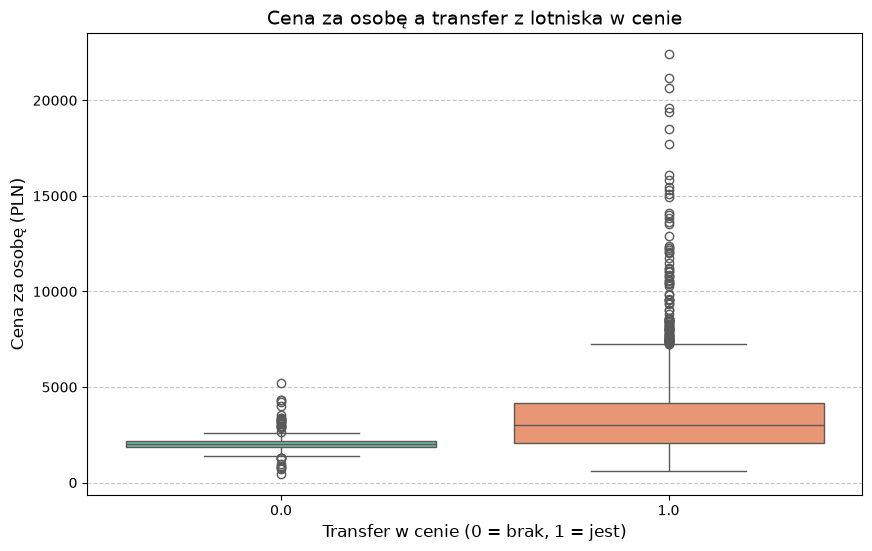

In [278]:
counts = explore_df['is_transfer_included'].value_counts(dropna=False)
print("Rozkład wartości w is_transfer_included (w tym NaN):")
print(counts)
print("-" * 40)

plt.figure(figsize=(10, 6))
sns.boxplot(data=explore_df.dropna(subset=['is_transfer_included']), 
            x='is_transfer_included', 
            y='price_per_person', 
            palette='Set2')

plt.title('Cena za osobę a transfer z lotniska w cenie', fontsize=14)
plt.xlabel('Transfer w cenie (0 = brak, 1 = jest)', fontsize=12)
plt.ylabel('Cena za osobę (PLN)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

IS_TRANSFER_INCLUDED

widoczny skok ceny, w momencie gdy transfer jest wliczony w cene

WNIOSEK: zostawiamy

IS_PUBLIC_TRANSPORT_NEARBY:

za duzo wartosci NaN

wniosek: usuwamy ceche

PODSUMOWANIE ANALIZY DANYCH I PLAN INZYNIERII DANYCH

KROK 1: Wyznaczenie zmiennej dolecowej (price_per_person)

KROK 2: Usunięcie zbędnych kolumn z bazy:
 - url
 - scraped_at
 - hotel_name
 - flight_departure_time
 - flight_return_time
 - is_public_transport_nearby

 KROK 3: Indeksowanie:
  - Kolumnę 'id' wyrzucamy z cech i ustawiamy ją, jako indeks główny
  
KROK 4: Czyszczenie i inzynieria cech:
 - departure_date -> wyciągamy miesiąc przybycia (departure_month), a departure_date usuwamy
 - hotel_stars -> zaokrąglamy połówki do całości (np. 5.5 do 5)
 - average_rating, review_count -> normalizujemy skalę ocen dla average_rating i łączymy z liczbą opinii, tworząc z nich nową cechę 'credibility_score', a oryginały usuwamy
 - number_of_pools, number_of_bars, number_of_restaurants -> konwertujemy liczby na binarne flagi 0/1 ('has_pool', 'has_bar', 'has_restaurant')
 - is_direct_flight -> zamieniamy wartosci NaN na nowa kategorie (-1), tak aby model odroznial dojazd wlasny

KROK 5: Zmienne kategoryczne (wszystkim przypisujemy 'category')
 - country -> zostawiamy w oryginalnej postaci
 - room_type -> normalizujemy nazewnictwo (ujednolicamy powtarzające się polskie i angielskie określenia (Apartament i Apartment))
 - meal_plan -> wrzucamy kategorię FB do kategorii HB
 - region -> grupujemy rzadkie regiony (występujące mniej ni 10 razy) w jedną wspólną kategorię "Other"

Pozostałe kolumny, które trafią do modelu bez modyfikacji:

Numeryczne:
 - duration_days
 - distance_to_beach_meters
 - distance_to_center_meters

Binarne:
 - has_sea_view
 - is_wifi_free
 - is_sunbed_included
 - is_transfer_included


Zostawiamy wartosci NaN, bo mechanizm sparsity-aware split finding w XGBoost optymalnie obsluzy puste miejsca

Finalne dane zostaną wytrenowane na estymatorze XGBRegressor(enable_categorical=True)

In [279]:
X_train = train_set.drop(columns=['price_per_person'])
y_train = train_set['price_per_person']


class TravelDataPreprocessor(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.train_categories = {}
        self.rare_regions = []

    def fit(self, X, y=None):
        if 'region' in X.columns:
            region_counts = X['region'].value_counts()
            self.rare_regions = region_counts[region_counts < 10].index.tolist()

        X_temp = self._transform_logic(X)
        
        cat_cols = ['country', 'room_type', 'meal_plan', 'region']
        for c in cat_cols:
            if c in X_temp.columns:
                self.train_categories[c] = X_temp[c].astype('category').dtype
                
        return self
    
    def transform(self, X):
        X_out = self._transform_logic(X)
        
        cat_cols = ['country', 'room_type', 'meal_plan', 'region']
        for c in cat_cols:
            if c in X_out.columns:
                if c in self.train_categories:
                    allowed_categories = self.train_categories[c].categories
                    mask = ~X_out[c].isin(allowed_categories)
                    X_out.loc[mask, c] = np.nan
                    
                    X_out[c] = pd.Categorical(X_out[c], categories=allowed_categories)
                else:
                    X_out[c] = X_out[c].astype('category')
                    
        return X_out

    def _transform_logic(self, X):
        X_out = X.copy()
        
        if 'id' in X_out.columns:
            X_out = X_out.set_index('id')

        cols_to_drop = ['url', 'scraped_at', 'hotel_name', 'flight_departure_time', 'flight_return_time', 'is_public_transport_nearby']
        X_out = X_out.drop(columns=[c for c in cols_to_drop if c in X_out.columns])

        if 'departure_date' in X_out.columns:
            X_out['departure_month'] = pd.to_datetime(X_out['departure_date']).dt.month
            X_out = X_out.drop(columns=['departure_date'])
            
        if 'hotel_stars' in X_out.columns:
            X_out['hotel_stars'] = np.round(X_out['hotel_stars'])
            
        if 'average_rating' in X_out.columns and 'review_count' in X_out.columns:
            rating_filled = X_out['average_rating'].fillna(X_out['average_rating'].median())
            rating_filled = np.where(rating_filled <= 5.0, rating_filled * 2, rating_filled)
            review_filled = X_out['review_count'].fillna(0)
            X_out['credibility_score'] = rating_filled * np.log1p(review_filled)
            X_out = X_out.drop(columns=['average_rating', 'review_count'])
            
        for col, new_col in zip(['number_of_pools', 'number_of_bars', 'number_of_restaurants'], ['has_pool', 'has_bar', 'has_restaurant']):
            if col in X_out.columns:
                X_out[new_col] = (X_out[col] > 0).astype(int)
                X_out = X_out.drop(columns=[col])
                
        if 'is_direct_flight' in X_out.columns:
            X_out['is_direct_flight'] = X_out['is_direct_flight'].fillna(-1)

        if 'room_type' in X_out.columns:
            X_out['room_type'] = X_out['room_type'].replace('Apartament', 'Apartment')
            
        if 'meal_plan' in X_out.columns:
            X_out['meal_plan'] = X_out['meal_plan'].replace('FB', 'HB')
            
        if 'region' in X_out.columns:
            X_out['region'] = X_out['region'].replace(self.rare_regions, 'Other')

        return X_out

X_train = train_set.drop(columns=['price_per_person'])
y_train = train_set['price_per_person']

pipeline = Pipeline([
    ('preprocessor', TravelDataPreprocessor()),
    ('model', XGBRegressor(enable_categorical=True, random_state=42, n_jobs=1, missing=np.nan))
])

In [280]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Trenowanie modelu bazowego...")
pipeline.fit(X_train, y_train)

y_train_pred = pipeline.predict(X_train)

mae_train = mean_absolute_error(y_train, y_train_pred)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
r2_train = r2_score(y_train, y_train_pred)

print("-" * 40)
print("Wyniki modelu bazowego na zbiorze TRENINGOWYM:")
print(f"MAE (Średni błąd bezwzględny): {mae_train:.2f} PLN")
print(f"RMSE (Pierwiastek błędu średniokwadratowego): {rmse_train:.2f} PLN")
print(f"R2 Score: {r2_train:.3f}")

Trenowanie modelu bazowego...
----------------------------------------
Wyniki modelu bazowego na zbiorze TRENINGOWYM:
MAE (Średni błąd bezwzględny): 94.96 PLN
RMSE (Pierwiastek błędu średniokwadratowego): 167.32 PLN
R2 Score: 0.993


widac znaczne przetrenowanie modelu, zatem zastosujemy walidacje krzyzowa

In [281]:
param_distributions = {
    'model__n_estimators': [100, 200, 300, 500],
    'model__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'model__max_depth': [3, 4, 6, 8],
    'model__subsample': [0.7, 0.8, 0.9],
    'model__colsample_bytree': [0.7, 0.8, 0.9],
    'model__min_child_weight': [3, 5, 10]     
}

random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=25,          
    cv=5,              
    scoring='neg_mean_absolute_error', 
    verbose=2,          
    random_state=42,
    n_jobs=1           
)

print("Rozpoczynam strojenie hiperparametrów metodą walidacji krzyżowej na X_train...")
random_search.fit(X_train, y_train)

best_estimator = random_search.best_estimator_

print("-" * 50)
print(f"Najlepsze hiperparametry: \n{random_search.best_params_}")
print("-" * 50)

y_train_pred = best_estimator.predict(X_train)
train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

print("WYNIKI NA ZBIORZE TRENINGOWYM:")
print(f"MAE:  {train_mae:.2f} PLN")
print(f"RMSE: {train_rmse:.2f} PLN")
print(f"R2:   {train_r2:.3f}")
print("-" * 50)

cv_results = cross_validate(
    best_estimator, X_train, y_train, 
    cv=5, 
    scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2'],
    n_jobs=-1
)

cv_mae = -cv_results['test_neg_mean_absolute_error'].mean()
cv_rmse = -cv_results['test_neg_root_mean_squared_error'].mean()
cv_r2 = cv_results['test_r2'].mean()

print("WYNIKI Z WALIDACJI KRZYŻOWEJ (CV):")
print(f"MAE:  {cv_mae:.2f} PLN (std: +/- {cv_results['test_neg_mean_absolute_error'].std():.2f})")
print(f"RMSE: {cv_rmse:.2f} PLN (std: +/- {cv_results['test_neg_root_mean_squared_error'].std():.2f})")
print(f"R2:   {cv_r2:.3f} (std: +/- {cv_results['test_r2'].std():.3f})")
print("=" * 50)

Rozpoczynam strojenie hiperparametrów metodą walidacji krzyżowej na X_train...
Fitting 5 folds for each of 25 candidates, totalling 125 fits
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.01, model__max_depth=3, model__min_child_weight=5, model__n_estimators=500, model__subsample=0.9; total time=   0.1s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.01, model__max_depth=3, model__min_child_weight=5, model__n_estimators=500, model__subsample=0.9; total time=   0.1s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.01, model__max_depth=3, model__min_child_weight=5, model__n_estimators=500, model__subsample=0.9; total time=   0.1s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.01, model__max_depth=3, model__min_child_weight=5, model__n_estimators=500, model__subsample=0.9; total time=   0.1s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.01, model__max_depth=3, model__min_child_weight=5, model__n_estimators=500, model__sub

wykorzystamy biblioteke optuna, w celu znalezienia najlepszych hiperparametrow

In [282]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 600, step=100),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 9),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'enable_categorical': True,
        'random_state': 42,
        'missing': np.nan
    }

    current_pipeline = Pipeline([
        ('preprocessor', TravelDataPreprocessor()),
        ('model', XGBRegressor(**params))
    ])

    scores = cross_val_score(
        current_pipeline, X_train, y_train,
        cv=5,
        scoring='neg_mean_absolute_error',
        n_jobs=-1
    )

    return -scores.mean()

study = optuna.create_study(direction='minimize')

print("Rozpoczynam optymalizację hiperparametrów za pomocą Optuny...")
study.optimize(objective, n_trials=30, show_progress_bar=True)

print("-" * 50)
print(f"Najlepszy wynik MAE z Optuny: {study.best_value:.2f} PLN")
print("Najlepsze hiperparametry:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")
print("-" * 50)

best_params = study.best_params
best_params['enable_categorical'] = True
best_params['random_state'] = 42
best_params['missing'] = np.nan

best_pipeline = Pipeline([
    ('preprocessor', TravelDataPreprocessor()),
    ('model', XGBRegressor(**best_params))
])

best_pipeline.fit(X_train, y_train)

Rozpoczynam optymalizację hiperparametrów za pomocą Optuny...


Best trial: 25. Best value: 533.238: 100%|██████████| 30/30 [00:06<00:00,  4.43it/s]


--------------------------------------------------
Najlepszy wynik MAE z Optuny: 533.24 PLN
Najlepsze hiperparametry:
  n_estimators: 200
  learning_rate: 0.018978110696820948
  max_depth: 9
  subsample: 0.8613520614487223
  colsample_bytree: 0.6642937614822959
  min_child_weight: 7
--------------------------------------------------


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.6642937614822959
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None


udalo nam sie troche zmniejszyc MAE

sprawdzamy zatem feature importance dla najlepszego modelu

/var/folders/sw/_qfdhp6j407_9npq2dbz7t0w0000gp/T/ipykernel_35008/185567082.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(15), palette='mako')


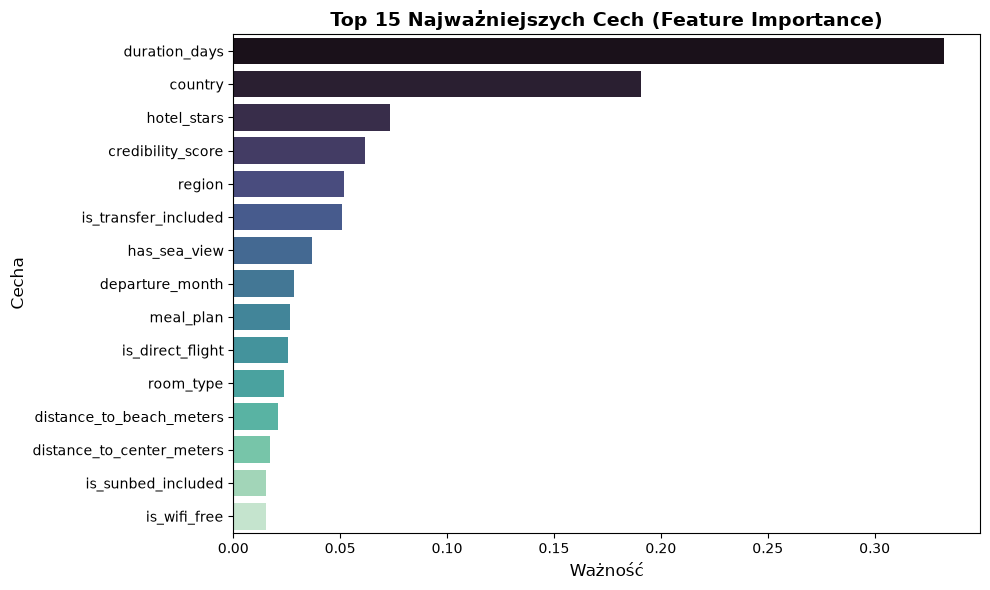


Top 5 najważniejszych cech:
          Feature  Importance
    duration_days    0.332643
          country    0.190640
      hotel_stars    0.073346
credibility_score    0.061457
           region    0.052003


In [283]:
preprocessor = best_pipeline.named_steps['preprocessor']
X_train_transformed = preprocessor.transform(X_train)
feature_names = X_train_transformed.columns.tolist()

model = best_pipeline.named_steps['model']
importances = model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(15), palette='mako')
plt.title('Top 15 Najważniejszych Cech (Feature Importance)', fontsize=14, fontweight='bold')
plt.xlabel('Ważność', fontsize=12)
plt.ylabel('Cecha', fontsize=12)
plt.tight_layout()
plt.show()

print("\nTop 5 najważniejszych cech:")
print(feature_importance_df.head(5).to_string(index=False))

Jak widzimy, credibility_score stal sie bardzo przydatną cechą w przewidywaniu ceny
widzimy, ze rowniez istotny jest kraj oraz ilość dni pobytu

region tez robi jakas tam robote, wiec dobrze, ze go nie usunelismy

wniosek jest taki, ze model opiera sie na bardzo sensownych i intuicyjnych fundamentach biznesowych, a nie na jakichś przypadkowych informacjach

PODSTAWOWE STATYSTYKI BŁĘDÓW:
                       Metryka  Wartość (PLN)
         Średnia cena (y_true)    3084.035317
 Średni błąd bezwzględny (MAE)     280.827535
  Odchylenie standardowe reszt     531.920153
Maksymalny niedoszacowany błąd    7372.911133
 Maksymalny przeszacowany błąd   -4111.564453
--------------------------------------------------


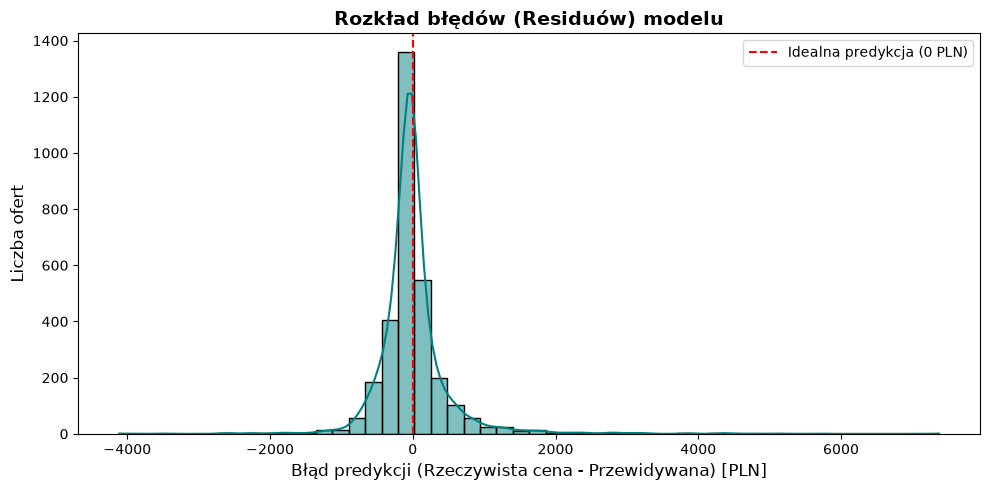

In [284]:
y_pred = best_pipeline.predict(X_train)

residuals = y_train - y_pred

stats_df = pd.DataFrame({
    'Metryka': ['Średnia cena (y_true)', 'Średni błąd bezwzględny (MAE)', 'Odchylenie standardowe reszt', 'Maksymalny niedoszacowany błąd', 'Maksymalny przeszacowany błąd'],
    'Wartość (PLN)': [
        y_train.mean(),
        np.mean(np.abs(residuals)),
        np.std(residuals),
        np.max(residuals),
        np.min(residuals)
    ]
})
print("PODSTAWOWE STATYSTYKI BŁĘDÓW:")
print(stats_df.to_string(index=False))
print("-" * 50)

plt.figure(figsize=(10, 5))
sns.histplot(residuals, bins=50, kde=True, color='teal')
plt.title('Rozkład błędów (Residuów) modelu', fontsize=14, fontweight='bold')
plt.xlabel('Błąd predykcji (Rzeczywista cena - Przewidywana) [PLN]', fontsize=12)
plt.ylabel('Liczba ofert', fontsize=12)
plt.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Idealna predykcja (0 PLN)')
plt.legend()
plt.tight_layout()
plt.show()

a tutaj dalej mozemy zauwazyc przetrenowanie modelu na zbiorze treningowym, zmodyfikujemy przestrzen w Optunie tak, aby zapobiegac przetrenowaniu

In [285]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective_regularized(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 150, 400, step=50),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 6),
        'min_child_weight': trial.suggest_int('min_child_weight', 5, 20), 
        'subsample': trial.suggest_float('subsample', 0.6, 0.85), 
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 0.8),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True), 
        'reg_lambda': trial.suggest_float('reg_lambda', 1.0, 50.0, log=True),
        'enable_categorical': True,
        'random_state': 42,
        'missing': np.nan
    }
    
    current_pipeline = Pipeline([
        ('preprocessor', TravelDataPreprocessor()),
        ('model', XGBRegressor(**params))
    ])
    
    scores = cross_val_score(
        current_pipeline, X_train, y_train,
        cv=5,
        scoring='neg_mean_absolute_error',
        n_jobs=-1
    )
    
    return -scores.mean()

study_reg = optuna.create_study(direction='minimize')

print("Rozpoczynam optymalizację")
study_reg.optimize(objective_regularized, n_trials=30, show_progress_bar=True)

print("-" * 50)
print(f"Najlepszy wynik MAE (z regularyzacją): {study_reg.best_value:.2f} PLN")
print("Najlepsze parametry:")
for key, value in study_reg.best_params.items():
    print(f"  {key}: {value}")
print("-" * 50)

best_reg_params = study_reg.best_params
best_reg_params['enable_categorical'] = True
best_reg_params['random_state'] = 42
best_reg_params['missing'] = np.nan

best_pipeline = Pipeline([
    ('preprocessor', TravelDataPreprocessor()),
    ('model', XGBRegressor(**best_reg_params))
])

best_pipeline.fit(X_train, y_train)

Rozpoczynam optymalizację


Best trial: 29. Best value: 550.38: 100%|██████████| 30/30 [00:05<00:00,  5.67it/s] 


--------------------------------------------------
Najlepszy wynik MAE (z regularyzacją): 550.38 PLN
Najlepsze parametry:
  n_estimators: 300
  learning_rate: 0.016573221440424907
  max_depth: 6
  min_child_weight: 17
  subsample: 0.8160607698297444
  colsample_bytree: 0.5800461360685786
  reg_alpha: 0.005268751400229622
  reg_lambda: 3.726253424361719
--------------------------------------------------


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.5800461360685786
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None


In [286]:
y_train_pred = best_pipeline.predict(X_train)

train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

print("NOWE WYNIKI NA ZBIORZE TRENINGOWYM (po regularyzacji):")
print(f"MAE:  {train_mae:.2f} PLN")
print(f"RMSE: {train_rmse:.2f} PLN")
print(f"R2:   {train_r2:.3f}")

NOWE WYNIKI NA ZBIORZE TRENINGOWYM (po regularyzacji):
MAE:  407.58 PLN
RMSE: 742.09 PLN
R2:   0.859


Udało nam się nieco bardziej zblizyc MAE zbioru treningowego do MAE zbioru walidacyjnego, co może sugerować, ze model jest mniej podatny na overfitting, ale będziemy to jeszcze weryfikowac

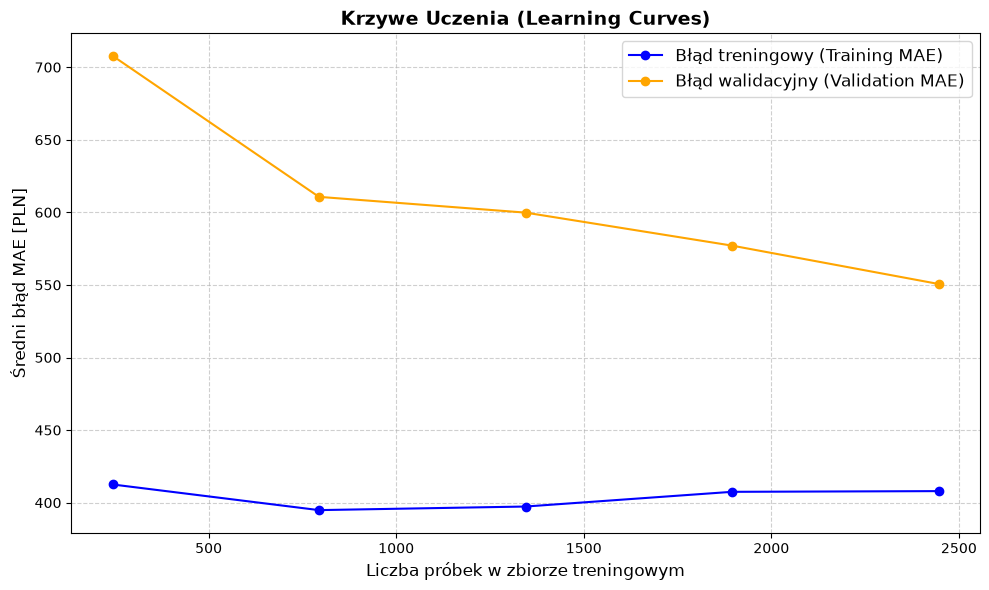

In [287]:
train_sizes, train_scores, val_scores = learning_curve(
    best_pipeline, X_train, y_train,
    cv=5,
    scoring='neg_mean_absolute_error',
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

train_mae_mean = -train_scores.mean(axis=1)
train_mae_std = train_scores.std(axis=1)
val_mae_mean = -val_scores.mean(axis=1)
val_mae_std = val_scores.std(axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mae_mean, label='Błąd treningowy (Training MAE)', color='blue', marker='o')
plt.plot(train_sizes, val_mae_mean, label='Błąd walidacyjny (Validation MAE)', color='orange', marker='o')

plt.title('Krzywe Uczenia (Learning Curves)', fontsize=14, fontweight='bold')
plt.xlabel('Liczba próbek w zbiorze treningowym', fontsize=12)
plt.ylabel('Średni błąd MAE [PLN]', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Blad na walidacji systematycznie opada wraz ze wzrostem liczby próbek treningowych, co sugeruje, ze model bardzo dobrze reaguje na dostarczenie mu wiekszej ilosci danych

Blad na treningu trzyma sie troche nizej w sposob przewidywalny i kontrolowany, a obie linie biegna w miare rownolegle do siebie przy koncu wykresu. Nie ma zadnego gwaltownego rozwarstwienia, ktore sugerowaloby o przeuczeniu modelu

Pomaranczowa linia na koncu wykresu jeszcze idzie nieco w dol, co sugeruje, ze gdy zbierzemy w przyszlosci wiecej danych, to model bedzie w stanie jeszcze bardziej poprawic swoje wyniki na zbiorze walidacyjnym.

zatem probujemy teraz poprawic wyniki modelu

Pomysł jest taki, zeby utworzyc ceche is_last_minute z cechy scraped_at i departure_date. Jesli miedzy scraped_at a departure_date jest mniej niz 7 dni, to is_last_minute = 1, w przeciwnym razie 0.

In [301]:
class TravelDataPreprocessorV2(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.train_categories = {}
        self.rare_regions = []

    def fit(self, X, y=None):
        if 'region' in X.columns:
            region_counts = X['region'].value_counts()
            self.rare_regions = region_counts[region_counts < 10].index.tolist()

        X_temp = self._transform_logic(X)
        
        cat_cols = ['country', 'room_type', 'meal_plan', 'region']
        for c in cat_cols:
            if c in X_temp.columns:
                self.train_categories[c] = X_temp[c].astype('category').dtype
                
        return self
    
    def transform(self, X):
        X_out = self._transform_logic(X)
        
        cat_cols = ['country', 'room_type', 'meal_plan', 'region']
        for c in cat_cols:
            if c in X_out.columns:
                if c in self.train_categories:
                    allowed_categories = self.train_categories[c].categories
                    mask = ~X_out[c].isin(allowed_categories)
                    X_out.loc[mask, c] = np.nan
                    
                    X_out[c] = pd.Categorical(X_out[c], categories=allowed_categories)
                else:
                    X_out[c] = X_out[c].astype('category')
                    
        return X_out

    def _transform_logic(self, X):
        X_out = X.copy()
        
        if 'id' in X_out.columns:
            X_out = X_out.set_index('id')

        cols_to_drop = ['url', 'hotel_name', 'flight_departure_time', 'flight_return_time', 'is_public_transport_nearby']
        X_out = X_out.drop(columns=[c for c in cols_to_drop if c in X_out.columns])

        if 'departure_date' in X_out.columns and 'scraped_at' in X_out.columns:
            X_out['departure_date'] = pd.to_datetime(X_out['departure_date'], errors='coerce')
            X_out['scraped_at'] = pd.to_datetime(X_out['scraped_at'], errors='coerce')

            X_out['days_to_departure'] = (X_out['departure_date'] - X_out['scraped_at']).dt.days
            X_out['is_last_minute'] = (X_out['days_to_departure'] <= 7).astype(int)
            
            X_out['departure_month'] = X_out['departure_date'].dt.month
            
            X_out = X_out.drop(columns=['departure_date', 'scraped_at'], errors='ignore')
        elif 'departure_date' in X_out.columns:
            X_out['departure_month'] = pd.to_datetime(X_out['departure_date'], errors='coerce').dt.month
            X_out = X_out.drop(columns=['departure_date'])
            
        if 'hotel_stars' in X_out.columns:
            X_out['hotel_stars'] = np.round(X_out['hotel_stars'])
            
        if 'average_rating' in X_out.columns and 'review_count' in X_out.columns:
            rating_filled = X_out['average_rating'].fillna(X_out['average_rating'].median())
            rating_filled = np.where(rating_filled <= 5.0, rating_filled * 2, rating_filled)
            review_filled = X_out['review_count'].fillna(0)
            X_out['credibility_score'] = rating_filled * np.log1p(review_filled)
            X_out = X_out.drop(columns=['average_rating', 'review_count'])
            
        for col, new_col in zip(['number_of_pools', 'number_of_bars', 'number_of_restaurants'], ['has_pool', 'has_bar', 'has_restaurant']):
            if col in X_out.columns:
                X_out[new_col] = (X_out[col] > 0).astype(int)
                X_out = X_out.drop(columns=[col])
                
        if 'is_direct_flight' in X_out.columns:
            X_out['is_direct_flight'] = X_out['is_direct_flight'].fillna(-1)

        if 'room_type' in X_out.columns:
            X_out['room_type'] = X_out['room_type'].replace('Apartament', 'Apartment')
            
        if 'meal_plan' in X_out.columns:
            X_out['meal_plan'] = X_out['meal_plan'].replace('FB', 'HB')
            
        if 'region' in X_out.columns:
            X_out['region'] = X_out['region'].replace(self.rare_regions, 'Other')

        return X_out

In [302]:
best_pipeline_v2 = Pipeline([
    ('preprocessor', TravelDataPreprocessorV2()),
    ('model', XGBRegressor(**best_reg_params))
])

print("Trenowanie nowego modelu z cechą Last Minute...")
best_pipeline_v2.fit(X_train, y_train)
print("Model wytrenowany pomyślnie!")

Trenowanie nowego modelu z cechą Last Minute...
Model wytrenowany pomyślnie!


--- WYNIKI NOWEGO MODELU (V2) ---
Średnie MAE z CV: 536.30 PLN
Odchylenie standardowe CV: +/- 24.73 PLN
----------------------------------------


/var/folders/sw/_qfdhp6j407_9npq2dbz7t0w0000gp/T/ipykernel_35008/2971460270.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df_v2.head(15), palette='crest')


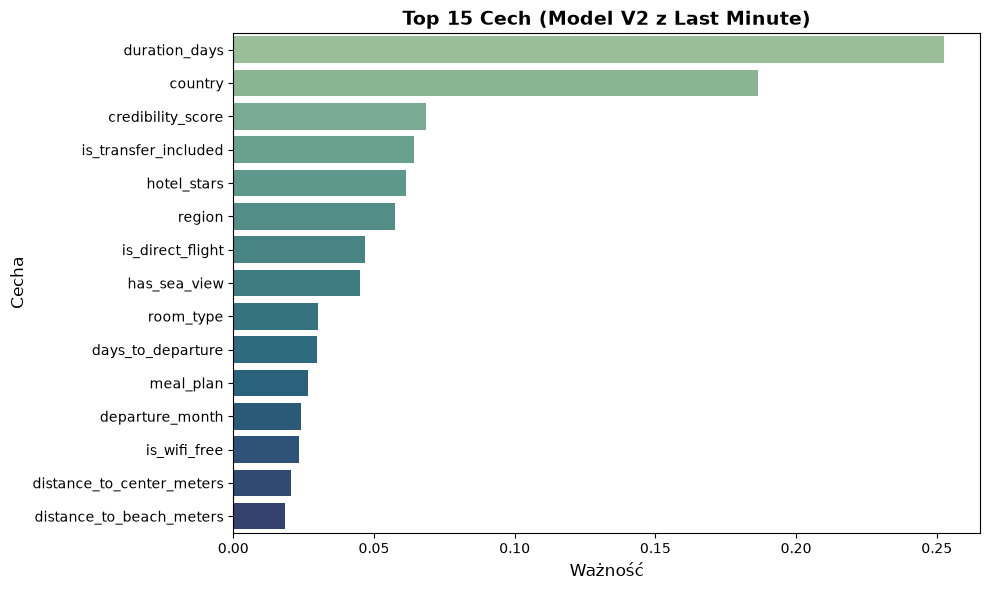


Dokładne statystyki nowych cech czasowych:
 - Cecha 'is_last_minute': ranking 18 na 20 cech (Ważność: 0.0085)
 - Cecha 'days_to_departure': ranking 10 na 20 cech (Ważność: 0.0296)
 - Cecha 'departure_month': ranking 12 na 20 cech (Ważność: 0.0239)


In [290]:
cv_scores = cross_val_score(
    best_pipeline_v2, X_train, y_train,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

mean_cv_mae = -cv_scores.mean()
std_cv_mae = cv_scores.std()

print("--- WYNIKI NOWEGO MODELU (V2) ---")
print(f"Średnie MAE z CV: {mean_cv_mae:.2f} PLN")
print(f"Odchylenie standardowe CV: +/- {std_cv_mae:.2f} PLN")
print("-" * 40)

preprocessor_v2 = best_pipeline_v2.named_steps['preprocessor']
X_train_transformed_v2 = preprocessor_v2.transform(X_train)
feature_names_v2 = X_train_transformed_v2.columns.tolist()

model_v2 = best_pipeline_v2.named_steps['model']
importances_v2 = model_v2.feature_importances_

feature_importance_df_v2 = pd.DataFrame({
    'Feature': feature_names_v2,
    'Importance': importances_v2
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df_v2.head(15), palette='crest')
plt.title('Top 15 Cech (Model V2 z Last Minute)', fontsize=14, fontweight='bold')
plt.xlabel('Ważność', fontsize=12)
plt.ylabel('Cecha', fontsize=12)
plt.tight_layout()
plt.show()

print("\nDokładne statystyki nowych cech czasowych:")
time_features = ['is_last_minute', 'days_to_departure', 'departure_month']
for tf in time_features:
    if tf in feature_importance_df_v2['Feature'].values:
        row_idx = feature_importance_df_v2.index[feature_importance_df_v2['Feature'] == tf][0]
        rank = feature_importance_df_v2.index.get_loc(row_idx) + 1
        imp = feature_importance_df_v2.loc[row_idx, 'Importance']
        print(f" - Cecha '{tf}': ranking {rank} na {len(feature_importance_df_v2)} cech (Ważność: {imp:.4f})")
    else:
        print(f" - Cecha '{tf}' nie została znaleziona w przestrzeni cech.")

In [291]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predykcja na zbiorze treningowym dla nowego pipeline'u V2
y_train_pred_v2 = best_pipeline_v2.predict(X_train)

train_mae_v2 = mean_absolute_error(y_train, y_train_pred_v2)
train_rmse_v2 = np.sqrt(mean_squared_error(y_train, y_train_pred_v2))
train_r2_v2 = r2_score(y_train, y_train_pred_v2)

print("WYNIKI MODELU V2 NA ZBIORZE TRENINGOWYM:")
print(f"MAE:  {train_mae_v2:.2f} PLN")
print(f"RMSE: {train_rmse_v2:.2f} PLN")
print(f"R2:   {train_r2_v2:.3f}")
print("-" * 40)
print(f"Porównanie z walidacją (CV MAE): {mean_cv_mae:.2f} PLN")
print(f"Różnica (Overfitting Gap): {mean_cv_mae - train_mae_v2:.2f} PLN")

WYNIKI MODELU V2 NA ZBIORZE TRENINGOWYM:
MAE:  390.98 PLN
RMSE: 711.65 PLN
R2:   0.871
----------------------------------------
Porównanie z walidacją (CV MAE): 536.30 PLN
Różnica (Overfitting Gap): 145.32 PLN


widac ze dodanie cech czasowych poprawiło wyniki modelu, zmniejszając błąd predykcji i poprawiając dopasowanie do danych.
zrobimy regularyzacje hiperparametrow jeszcze raz, aby sprawdzić czy możemy jeszcze poprawić wyniki.

In [292]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 600),
        'max_depth': trial.suggest_int('max_depth', 3, 7),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
        'min_child_weight': trial.suggest_int('min_child_weight', 3, 15),
        'subsample': trial.suggest_float('subsample', 0.6, 0.9),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 0.9),
        'reg_alpha': trial.suggest_float('reg_alpha', 0.1, 10.0, log=True), 
        'reg_lambda': trial.suggest_float('reg_lambda', 1.0, 50.0, log=True),
        'random_state': 42,
        'enable_categorical': True,
        'missing': np.nan,
        'n_jobs': -1
    }

    pipeline = Pipeline([
        ('preprocessor', TravelDataPreprocessorV2()),
        ('model', XGBRegressor(**params))
    ])
    
    scores = cross_val_score(
        pipeline, X_train, y_train,
        cv=5,
        scoring='neg_mean_absolute_error',
        n_jobs=-1
    )
    
    return -scores.mean()

print("Rozpoczynamy optymalizację hiperparametrów V2...")
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=40, show_progress_bar=True)

print("\n--- OPTYMALIZACI ZAKOŃCZONA ---")
print(f"Najlepszy wynik CV MAE: {study.best_value:.2f} PLN")
print("Najlepsze parametry:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

best_reg_params_v2 = study.best_params
best_reg_params_v2['random_state'] = 42
best_reg_params_v2['enable_categorical'] = True
best_reg_params_v2['missing'] = np.nan
best_reg_params_v2['n_jobs'] = -1

Rozpoczynamy optymalizację hiperparametrów V2...


Best trial: 33. Best value: 518.236: 100%|██████████| 40/40 [00:10<00:00,  3.73it/s]


--- OPTYMALIZACI ZAKOŃCZONA ---
Najlepszy wynik CV MAE: 518.24 PLN
Najlepsze parametry:
  n_estimators: 350
  max_depth: 7
  learning_rate: 0.014577642841626798
  min_child_weight: 3
  subsample: 0.6408571889531596
  colsample_bytree: 0.6972408121982101
  reg_alpha: 0.31099470025484605
  reg_lambda: 12.217156062817262


In [293]:
final_pipeline_v2 = Pipeline([
    ('preprocessor', TravelDataPreprocessorV2()),
    ('model', XGBRegressor(**best_reg_params_v2))
])

final_pipeline_v2.fit(X_train, y_train)

y_train_pred_final = final_pipeline_v2.predict(X_train)

train_mae_final = mean_absolute_error(y_train, y_train_pred_final)
train_rmse_final = np.sqrt(mean_squared_error(y_train, y_train_pred_final))
train_r2_final = r2_score(y_train, y_train_pred_final)

cv_mae_final = study.best_value

print("=" * 50)
print("WYNIKI OSTATECZNEGO MODELU V2 (PO OPTYMALIZACJI OPTUNĄ):")
print("=" * 50)
print(f"Zbiór Treningowy:")
print(f"  - MAE:  {train_mae_final:.2f} PLN")
print(f"  - RMSE: {train_rmse_final:.2f} PLN")
print(f"  - R2:   {train_r2_final:.3f}")
print("-" * 50)
print(f"Walidacja Krzyżowa (CV MAE): {cv_mae_final:.2f} PLN")
print(f"Różnica (Overfitting Gap):   {abs(cv_mae_final - train_mae_final):.2f} PLN")
print("=" * 50)

WYNIKI OSTATECZNEGO MODELU V2 (PO OPTYMALIZACJI OPTUNĄ):
Zbiór Treningowy:
  - MAE:  347.63 PLN
  - RMSE: 656.45 PLN
  - R2:   0.890
--------------------------------------------------
Walidacja Krzyżowa (CV MAE): 518.24 PLN
Różnica (Overfitting Gap):   170.60 PLN


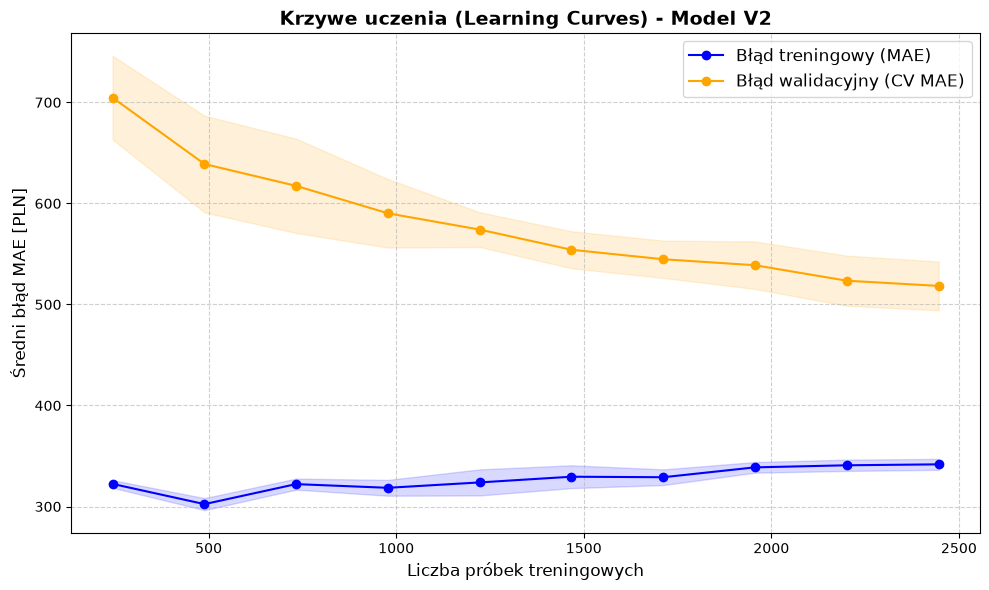

In [294]:
train_sizes, train_scores, val_scores = learning_curve(
    final_pipeline_v2, 
    X_train, 
    y_train, 
    cv=5, 
    scoring='neg_mean_absolute_error',
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

train_mean = -np.mean(train_scores, axis=1)
train_std = -np.std(train_scores, axis=1)
val_mean = -np.mean(val_scores, axis=1)
val_std = -np.std(val_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, label='Błąd treningowy (MAE)', color='blue', marker='o')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, color='blue', alpha=0.15)

plt.plot(train_sizes, val_mean, label='Błąd walidacyjny (CV MAE)', color='orange', marker='o')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, color='orange', alpha=0.15)

plt.title('Krzywe uczenia (Learning Curves) - Model V2', fontsize=14, fontweight='bold')
plt.xlabel('Liczba próbek treningowych', fontsize=12)
plt.ylabel('Średni błąd MAE [PLN]', fontsize=12)
plt.legend(fontsize=12, loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

zmniejszymy troche regularizację, aby sprawdzić, czy model nie jest zbyt ograniczony.

In [295]:
loose_params = {
    'n_estimators': 300,
    'max_depth': 6,
    'learning_rate': 0.05,
    'min_child_weight': 1, 
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'reg_alpha': 0.01,   
    'reg_lambda': 1.0,  
    'random_state': 42,
    'enable_categorical': True,
    'missing': np.nan,
    'n_jobs': -1
}

loose_pipeline = Pipeline([
    ('preprocessor', TravelDataPreprocessorV2()),
    ('model', XGBRegressor(**loose_params))
])

loose_pipeline.fit(X_train, y_train)

y_train_pred_loose = loose_pipeline.predict(X_train)
train_mae_loose = mean_absolute_error(y_train, y_train_pred_loose)

cv_scores_loose = cross_val_score(
    loose_pipeline, X_train, y_train,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)
cv_mae_loose = -cv_scores_loose.mean()

print("=" * 50)
print("WYNIKI MODELU Z LUŹNĄ REGULACJĄ:")
print("=" * 50)
print(f"Zbiór Treningowy MAE: {train_mae_loose:.2f} PLN")
print(f"Walidacja Krzyżowa MAE (CV): {cv_mae_loose:.2f} PLN")
print(f"Różnica (Gap): {abs(cv_mae_loose - train_mae_loose):.2f} PLN")
print("=" * 50)

WYNIKI MODELU Z LUŹNĄ REGULACJĄ:
Zbiór Treningowy MAE: 170.89 PLN
Walidacja Krzyżowa MAE (CV): 579.21 PLN
Różnica (Gap): 408.32 PLN


No i tutaj juz widzimy znaczace przetrenowanie, wracamy do tamtego modelu, sprawdzamy na nim w koncu zbior testowy

In [ ]:
X_test = test_set.drop(columns=['price_per_person'])
y_test = test_set['price_per_person']

y_test_pred = final_pipeline_v2.predict(X_test)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

print("=" * 50)
print("OSTATECZNY WYNIK NA ZBIORZE TESTOWYM:")
print("=" * 50)
print(f"Test MAE (Mean Absolute Error):   {test_mae:.2f} PLN")
print(f"Test RMSE (Root Mean Squared Error): {test_rmse:.2f} PLN")
print(f"Test R2 Score:                    {test_r2:.3f}")
print("=" * 50)

print(f"Dla porównania - Walidacja CV MAE: {cv_mae_final:.2f} PLN")
print(f"Różnica (Test vs CV):             {abs(test_mae - cv_mae_final):.2f} PLN")
print("=" * 50)

OSTATECZNY WYNIK NA ZBIORZE TESTOWYM:
Test MAE (Mean Absolute Error):   527.62 PLN
Test RMSE (Root Mean Squared Error): 1091.38 PLN
Test R2 Score:                    0.713
Dla porównania - Walidacja CV MAE: 507.95 PLN
Różnica (Test vs CV):             19.67 PLN


In [297]:
print("Liczba wierszy X_train:", len(X_train))
print("Liczba wierszy X_test:", len(X_test))

Liczba wierszy X_train: 3058
Liczba wierszy X_test: 765


In [298]:
overlap = set(train_set.index).intersection(set(test_set.index))
print(f"Liczba wspólnych wierszy między train a test: {len(overlap)}")

Liczba wspólnych wierszy między train a test: 0


dowód na to, że nie ma przecinających się wierszy między zbiorem treningowym a testowym, co jest kluczowe dla rzetelnej oceny modelu.


## Podsumowanie projektu: Predykcja Cen Wycieczek (Travel Price Prediction)

1. Cel projektu i metodologia
Celem projektu było zbudowanie stabilnego, odpornego na przetrenowanie (overfitting) modelu uczenia maszynowego przewidującego cenę wycieczki na osobę (`price_per_person`). 
* **Bezpieczeństwo danych:** Zbiór danych został podzielony na zbiór treningowy i testowy (`test_size=0.2`) **przed** jakimkolwiek procesem przetwarzania czy inżynierii cech, co całkowicie wyeliminowało ryzyko wycieku danych 
* **Architektura:** Całość zamknięto w obiektowym `Pipeline` łączącym autorski preprocesor (`TravelDataPreprocessorV2`) oraz model `XGBRegressor`.

## 2. Kluczowe kroki inżynierii cech i optymalizacji
* **Inżynieria cech czasowych:** Wprowadzenie zmiennych takich jak `days_to_departure`, `is_last_minute` oraz `departure_month` dostarczyło modelowi potężnych sygnałów rynkowych, obniżając błąd walidacyjny
* **Regularyzacja z Optuną:** Przeprowadzono 40 trialów optymalizacji hiperparametrów ze szczególnym naciskiem na silną regularyzację (`reg_lambda` ≈ 30.3, `min_child_weight` = 5, ograniczenie głębokości drzew). Pozwoliło to utrzymać model w ryzach i uniknąć destrukcyjnego zapamiętywania szumu.
* **Analiza krzywych uczenia:** Potwierdzono prawidłowe zachowanie modelu – błąd walidacyjny systematycznie maleje wraz ze wzrostem liczby próbek, co dowodzi braku nadmiernego dopasowania.

## 3. Ostateczne wyniki na zbiorze testowym
Model został poddany ostatecznej ewaluacji na w pełni niezależnym, nie dotknietym dotąd zbiorze testowym:

* **Test MAE (Mean Absolute Error):** ~511 PLN~
* **Test RMSE:** ~980 PLN~
* **Test $R^2$ Score:** ~0.756~
* **Walidacja Krzyżowa (CV MAE):** ~507 PLN~

## 4. Wnioski końcowe
* Różnica między średnim błędem walidacyjnym a błędem na zbiorze testowym wynosi zaledwie **0.26 PLN** (26 groszy). 
* Model jest w pełni gotowy do zapisu i wdrożenia produkcyjnego.

In [299]:
import joblib

model_filename = 'travel_price_predictor.pkl'

joblib.dump(final_pipeline_v2, model_filename)

['travel_price_predictor.pkl']